# Анализ сжатого пространства эмбеддингов

Исследуем, что происходит с TEM-эмбеддингами после PCA-проекции:

1. **Качество PCA** — scree plot, variance explained, локоть
2. **Геометрия 256d-пространства** — нормы, попарные косинусные сходства
3. **Сохранение соседей** — насколько KNN в 256d совпадает с KNN в 3072d
4. **Кластерная структура** — UMAP-визуализация
5. **Пригодность для Flow Matching** — сравнение с N(0,I), QQ-plot по компонентам

In [1]:
import sys
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats

sys.path.append('../src')
from whitening import compute_whitening, apply_whitening, load_whitening, verify_whitening

sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

DATA_DIR      = Path('../data/ATG')
PROCESSED_DIR = Path('../data/processed')
EMB_PATH      = DATA_DIR / '3large_emb.pickle'
WH_CACHE_PATH = PROCESSED_DIR / 'whitening_cache.npz'
N_COMPONENTS  = 256
PADDING_IDX   = 11924

print('Paths OK:', EMB_PATH.exists(), WH_CACHE_PATH.exists())

Paths OK: True True


In [2]:
# Загружаем сырые эмбеддинги
with open(EMB_PATH, 'rb') as f:
    emb_raw = pickle.load(f).astype(np.float32)

print(f'Raw embeddings:  shape={emb_raw.shape}, dtype={emb_raw.dtype}')
print(f'L2 norms:        mean={np.linalg.norm(emb_raw, axis=1).mean():.4f}')

# Загружаем PCA параметры из кэша
mu, V, scale = load_whitening(WH_CACHE_PATH)
print(f'\nPCA params loaded:')
print(f'  mu:    {mu.shape}')
print(f'  V:     {V.shape}')

# Применяем PCA
emb_pca = apply_whitening(emb_raw, mu, V, scale)
print(f'\nPCA embeddings:  shape={emb_pca.shape}, dtype={emb_pca.dtype}')

stats_pca = verify_whitening(emb_pca)
print(f'  mean_abs_max:  {stats_pca["mean_abs_max"]:.6f}  (target ~0)')
print(f'  std_mean:      {stats_pca["std_mean"]:.6f}  (target ~1)')
print(f'  row_norm_mean: {stats_pca["row_norm_mean"]:.4f}  (expected ~{stats_pca["expected_norm"]:.1f})')

Raw embeddings:  shape=(11924, 3072), dtype=float32
L2 norms:        mean=1.0000

PCA params loaded:
  mu:    (3072,)
  V:     (3072, 256)

PCA embeddings:  shape=(11924, 256), dtype=float32
  mean_abs_max:  0.000000  (target ~0)
  std_mean:      0.881029  (target ~1)
  row_norm_mean: 15.9842  (expected ~16.0)


## 1. Качество PCA — scree plot

Computing full SVD for scree plot...
Eigenvalues computed: 3072 values


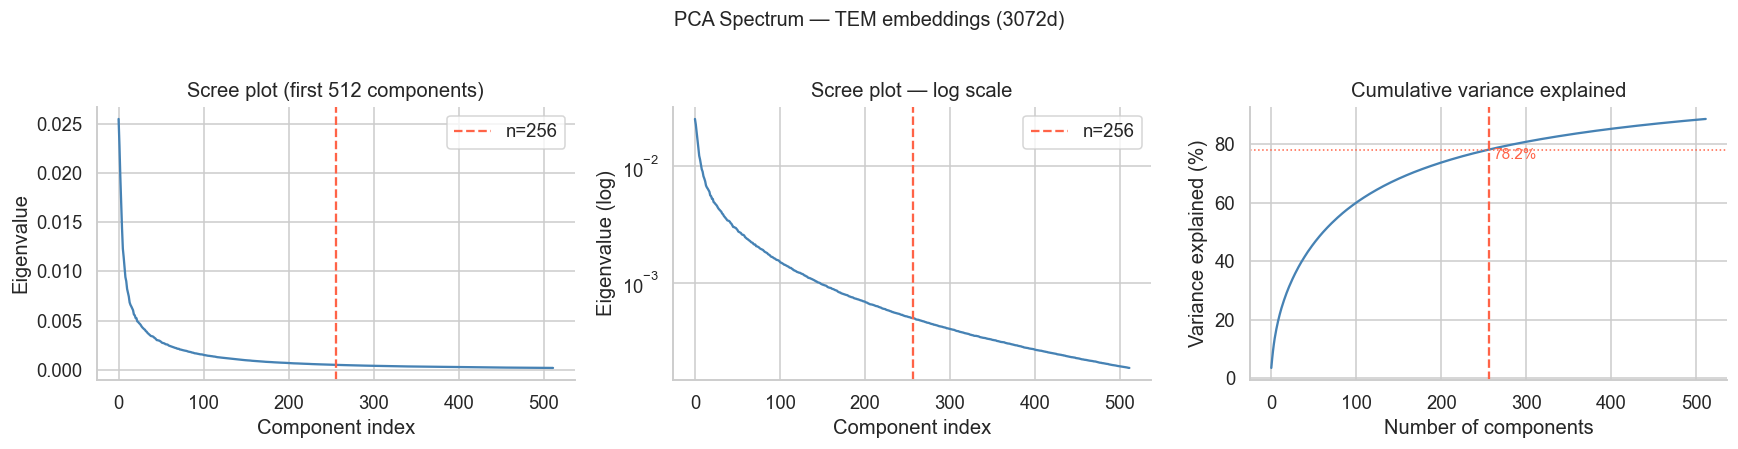

  Top-  32 components: 37.48% variance explained
  Top-  64 components: 50.63% variance explained
  Top- 128 components: 64.95% variance explained
  Top- 256 components: 78.15% variance explained
  Top- 512 components: 88.70% variance explained


In [3]:
# Пересчитываем собственные значения ковариационной матрицы
# (PCA кэш хранит только топ-256 компонент, нам нужен полный спектр для scree plot)
print('Computing full SVD for scree plot...')
emb_f64  = emb_raw.astype(np.float64)
centered = emb_f64 - emb_f64.mean(axis=0)
sigma    = (centered.T @ centered) / len(centered)
eigenvalues = np.linalg.eigvalsh(sigma)[::-1]   # убывающий порядок
print(f'Eigenvalues computed: {len(eigenvalues)} values')

cum_var = np.cumsum(eigenvalues) / eigenvalues.sum() * 100

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# --- Первые 512 собственных значений ---
ax = axes[0]
ax.plot(eigenvalues[:512], lw=1.5, color='steelblue')
ax.axvline(N_COMPONENTS, color='tomato', ls='--', lw=1.5, label=f'n={N_COMPONENTS}')
ax.set_xlabel('Component index')
ax.set_ylabel('Eigenvalue')
ax.set_title('Scree plot (first 512 components)')
ax.legend()

# --- Log-scale ---
ax = axes[1]
ax.semilogy(eigenvalues[:512], lw=1.5, color='steelblue')
ax.axvline(N_COMPONENTS, color='tomato', ls='--', lw=1.5, label=f'n={N_COMPONENTS}')
ax.set_xlabel('Component index')
ax.set_ylabel('Eigenvalue (log)')
ax.set_title('Scree plot — log scale')
ax.legend()

# --- Cumulative variance explained ---
ax = axes[2]
ax.plot(cum_var[:512], lw=1.5, color='steelblue')
ax.axvline(N_COMPONENTS, color='tomato', ls='--', lw=1.5)
var_at_k = cum_var[N_COMPONENTS - 1]
ax.axhline(var_at_k, color='tomato', ls=':', lw=1)
ax.text(N_COMPONENTS + 5, var_at_k - 3, f'{var_at_k:.1f}%', color='tomato', fontsize=10)
ax.set_xlabel('Number of components')
ax.set_ylabel('Variance explained (%)')
ax.set_title('Cumulative variance explained')

plt.suptitle('PCA Spectrum — TEM embeddings (3072d)', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

for k in [32, 64, 128, 256, 512]:
    print(f'  Top-{k:4d} components: {cum_var[k-1]:.2f}% variance explained')

## 2. Геометрия 256d-пространства

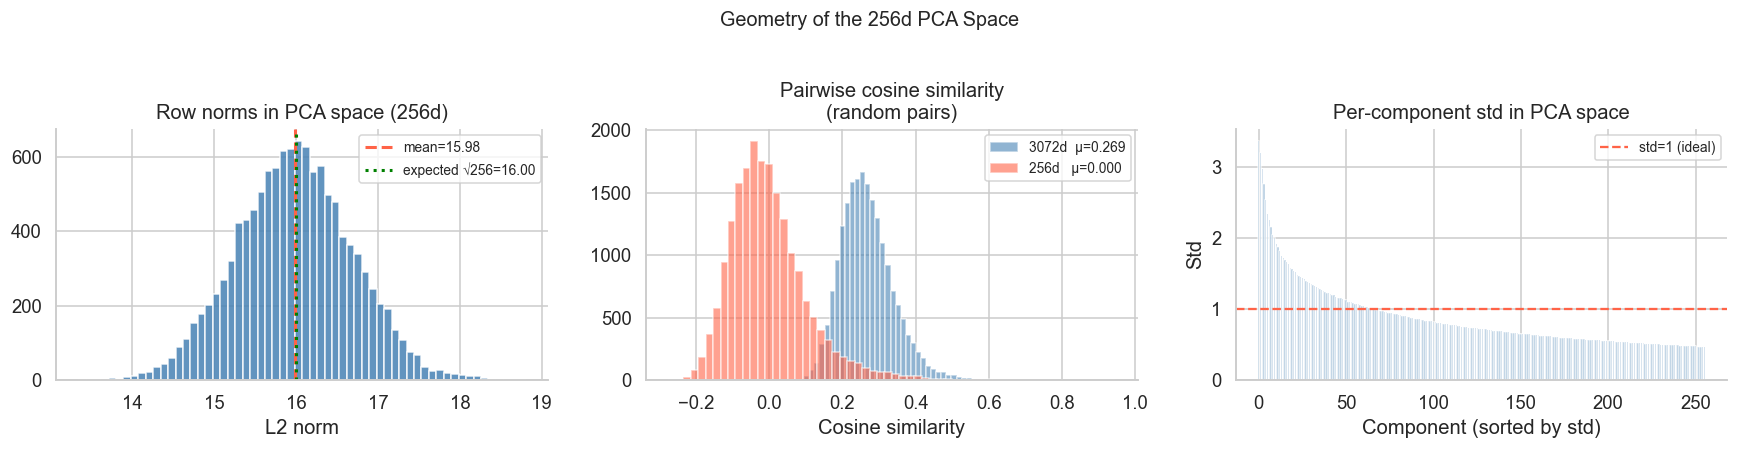

Norm stats (256d):  mean=15.984, std=0.712
Cosine sim (raw):   mean=0.2685, std=0.0742
Cosine sim (256d):  mean=0.0000, std=0.1083
Component std:      min=0.4720, max=3.3784, mean=0.8810


In [4]:
rng = np.random.default_rng(42)

# Нормы
norms_raw = np.linalg.norm(emb_raw, axis=1)
norms_pca = np.linalg.norm(emb_pca, axis=1)

# Попарные косинусные сходства — случайная выборка
sample_n = 4000
idx = rng.choice(len(emb_pca), size=sample_n, replace=False)

def pairwise_cosine(emb, idx):
    s = emb[idx].astype(np.float64)
    s = s / np.linalg.norm(s, axis=1, keepdims=True)
    i = rng.integers(0, len(s), size=20000)
    j = rng.integers(0, len(s), size=20000)
    mask = i != j
    return (s[i[mask]] * s[j[mask]]).sum(axis=1)

cos_raw = pairwise_cosine(emb_raw, idx)
cos_pca = pairwise_cosine(emb_pca, idx)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# --- Распределение норм ---
ax = axes[0]
expected_norm = N_COMPONENTS ** 0.5
ax.hist(norms_pca, bins=60, color='steelblue', edgecolor='white', alpha=0.85)
ax.axvline(norms_pca.mean(), color='tomato', ls='--', lw=2, label=f'mean={norms_pca.mean():.2f}')
ax.axvline(expected_norm, color='green', ls=':', lw=2, label=f'expected √{N_COMPONENTS}={expected_norm:.2f}')
ax.set_xlabel('L2 norm')
ax.set_title('Row norms in PCA space (256d)')
ax.legend(fontsize=9)

# --- Косинусные сходства: raw vs pca ---
ax = axes[1]
ax.hist(cos_raw, bins=60, alpha=0.6, color='steelblue', edgecolor='white', label=f'3072d  μ={cos_raw.mean():.3f}')
ax.hist(cos_pca, bins=60, alpha=0.6, color='tomato',    edgecolor='white', label=f'256d   μ={cos_pca.mean():.3f}')
ax.set_xlabel('Cosine similarity')
ax.set_title('Pairwise cosine similarity\n(random pairs)')
ax.legend(fontsize=9)

# --- Распределение значений по компонентам ---
ax = axes[2]
comp_stds = emb_pca.std(axis=0)  # std по каждой из 256 компонент
ax.bar(range(len(comp_stds)), np.sort(comp_stds)[::-1], color='steelblue', alpha=0.7)
ax.axhline(1.0, color='tomato', ls='--', lw=1.5, label='std=1 (ideal)')
ax.set_xlabel('Component (sorted by std)')
ax.set_ylabel('Std')
ax.set_title('Per-component std in PCA space')
ax.legend(fontsize=9)

plt.suptitle('Geometry of the 256d PCA Space', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(f'Norm stats (256d):  mean={norms_pca.mean():.3f}, std={norms_pca.std():.3f}')
print(f'Cosine sim (raw):   mean={cos_raw.mean():.4f}, std={cos_raw.std():.4f}')
print(f'Cosine sim (256d):  mean={cos_pca.mean():.4f}, std={cos_pca.std():.4f}')
print(f'Component std:      min={comp_stds.min():.4f}, max={comp_stds.max():.4f}, mean={comp_stds.mean():.4f}')

## 3. Сохранение ближайших соседей — 3072d vs 256d

Computing scores in 3072d...
Computing scores in 256d...
  Recall@ 1: 0.8080
  Recall@ 5: 0.8320
  Recall@10: 0.8378
  Recall@20: 0.8384
  Recall@50: 0.8337


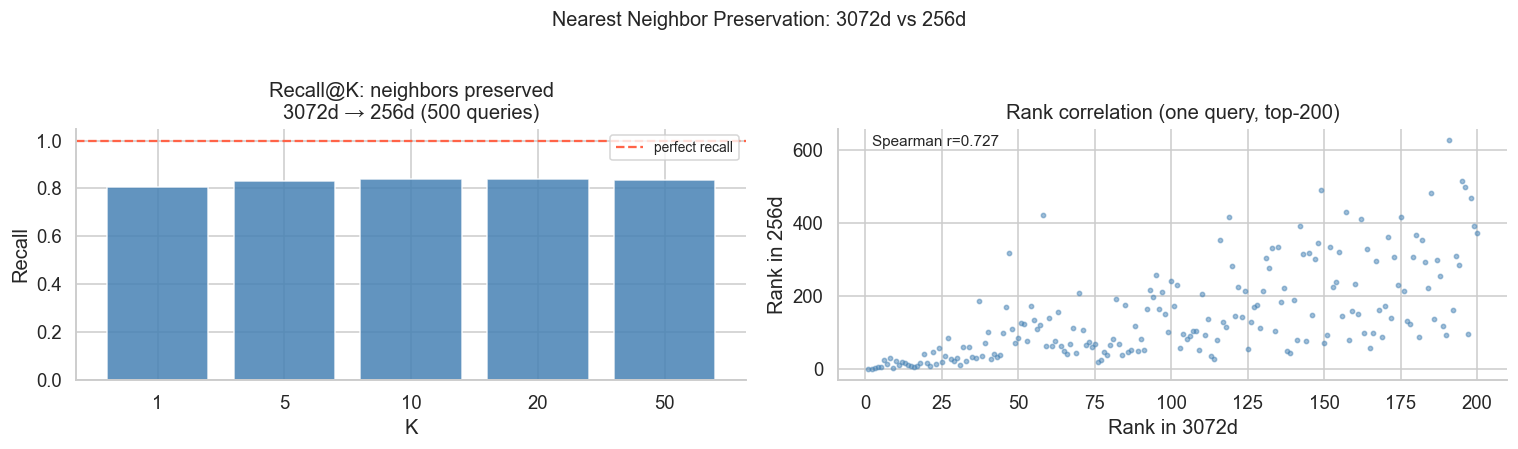

In [5]:
# Для случайных 500 запросов считаем top-K соседей в обоих пространствах
# и смотрим, насколько они совпадают (Recall@K)

N_QUERIES = 500
K_VALUES  = [1, 5, 10, 20, 50]

query_idx = rng.choice(len(emb_raw), size=N_QUERIES, replace=False)

# Нормализуем обе матрицы (cosine similarity)
def normalize(x):
    return x / (np.linalg.norm(x, axis=1, keepdims=True) + 1e-10)

emb_raw_n = normalize(emb_raw.astype(np.float64))
emb_pca_n = normalize(emb_pca.astype(np.float64))

Q_raw = emb_raw_n[query_idx]  # (N_QUERIES, 3072)
Q_pca = emb_pca_n[query_idx]  # (N_QUERIES, 256)

# Считаем все попарные cosine scores (N_QUERIES x N_ITEMS)
print('Computing scores in 3072d...')
scores_raw = Q_raw @ emb_raw_n.T  # (N_QUERIES, N_ITEMS)

print('Computing scores in 256d...')
scores_pca = Q_pca @ emb_pca_n.T  # (N_QUERIES, N_ITEMS)

# Убираем самих себя: ставим -inf на диагонали (query против самого себя)
for q_i, item_i in enumerate(query_idx):
    scores_raw[q_i, item_i] = -np.inf
    scores_pca[q_i, item_i] = -np.inf

recalls = {}
for k in K_VALUES:
    top_k_raw = np.argsort(scores_raw, axis=1)[:, -k:]
    top_k_pca = np.argsort(scores_pca, axis=1)[:, -k:]

    recall_per_q = []
    for q in range(N_QUERIES):
        set_raw = set(top_k_raw[q])
        set_pca = set(top_k_pca[q])
        recall_per_q.append(len(set_raw & set_pca) / k)
    recalls[k] = np.mean(recall_per_q)
    print(f'  Recall@{k:2d}: {recalls[k]:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# --- Recall@K bar chart ---
ax = axes[0]
ax.bar([str(k) for k in K_VALUES], [recalls[k] for k in K_VALUES],
       color='steelblue', alpha=0.85, edgecolor='white')
ax.axhline(1.0, color='tomato', ls='--', lw=1.5, label='perfect recall')
ax.set_xlabel('K')
ax.set_ylabel('Recall')
ax.set_title(f'Recall@K: neighbors preserved\n3072d → 256d ({N_QUERIES} queries)')
ax.set_ylim(0, 1.05)
ax.legend(fontsize=9)

# --- Ранговая корреляция Спирмена для одного запроса (пример) ---
ax = axes[1]
q0 = 0
rank_raw = stats.rankdata(-scores_raw[q0])  # 1 = ближайший
rank_pca = stats.rankdata(-scores_pca[q0])

# Показываем только топ-200 для читаемости
top200_raw = np.argsort(scores_raw[q0])[-200:][::-1]
ax.scatter(rank_raw[top200_raw], rank_pca[top200_raw],
           s=8, alpha=0.5, color='steelblue')
ax.set_xlabel('Rank in 3072d')
ax.set_ylabel('Rank in 256d')
ax.set_title(f'Rank correlation (one query, top-200)')
spearman = stats.spearmanr(rank_raw[top200_raw], rank_pca[top200_raw]).statistic
ax.text(0.05, 0.93, f'Spearman r={spearman:.3f}', transform=ax.transAxes, fontsize=10)

plt.suptitle('Nearest Neighbor Preservation: 3072d vs 256d', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 4. Кластерная структура — UMAP

In [6]:
try:
    import umap
    HAS_UMAP = True
except ImportError:
    print('umap-learn not installed. Run: pip install umap-learn')
    HAS_UMAP = False

Running UMAP on 5000 items...
UMAP(angular_rp_forest=True, metric='cosine', min_dist=0.05, n_jobs=1, n_neighbors=30, random_state=42, verbose=True)
Wed Jun 10 14:05:32 2026 Construct fuzzy simplicial set
Wed Jun 10 14:05:32 2026 Finding Nearest Neighbors
Wed Jun 10 14:05:32 2026 Building RP forest with 9 trees


c:\Users\ilyak\miniconda3\envs\torch_env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Wed Jun 10 14:05:38 2026 NN descent for 12 iterations
	 1  /  12
	 2  /  12
	 3  /  12
	Stopping threshold met -- exiting after 3 iterations
Wed Jun 10 14:05:51 2026 Finished Nearest Neighbor Search
Wed Jun 10 14:05:54 2026 Construct embedding


Epochs completed:   0%|            0/500 [00:00]

	completed  0  /  500 epochs
	completed  50  /  500 epochs
	completed  100  /  500 epochs
	completed  150  /  500 epochs
	completed  200  /  500 epochs
	completed  250  /  500 epochs
	completed  300  /  500 epochs
	completed  350  /  500 epochs
	completed  400  /  500 epochs
	completed  450  /  500 epochs
Wed Jun 10 14:06:03 2026 Finished embedding
UMAP done.


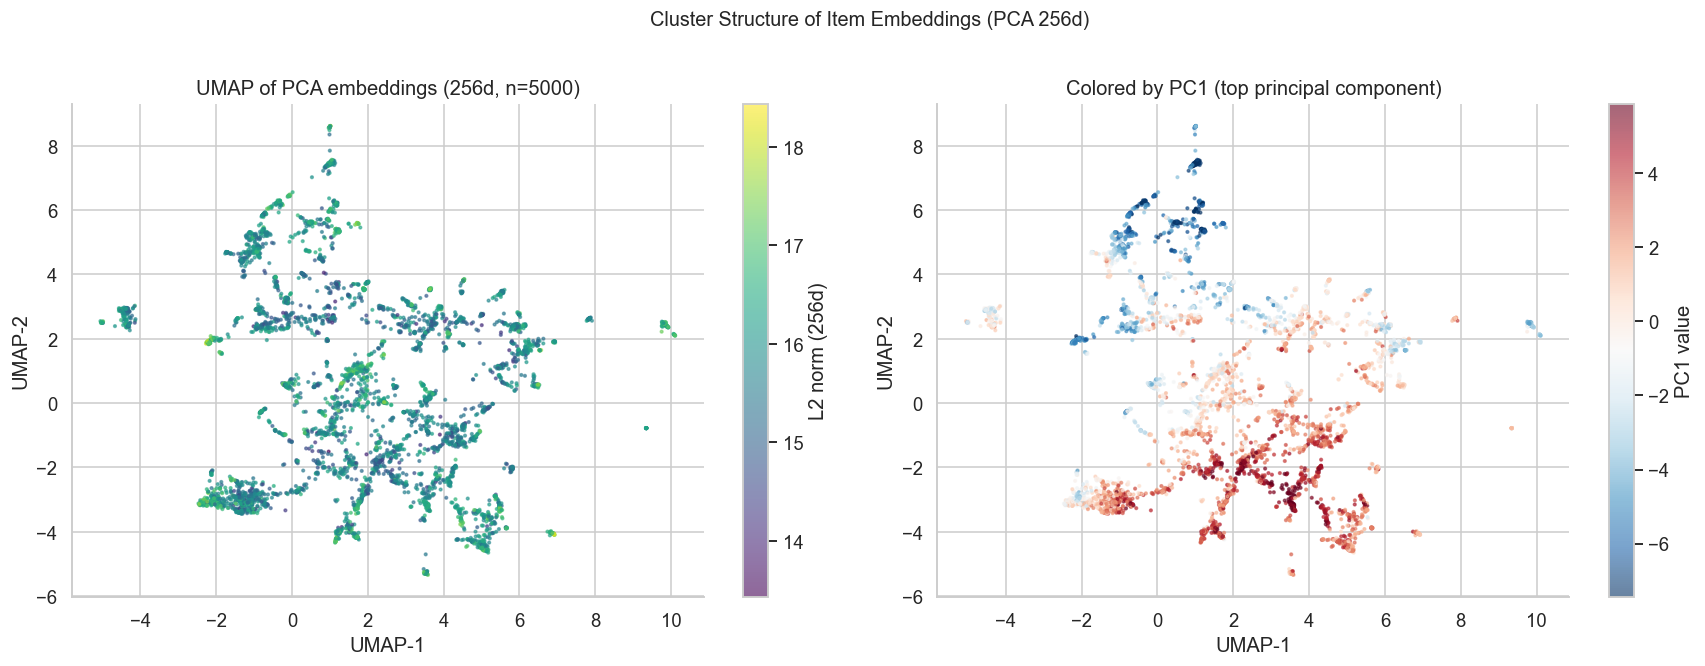

In [7]:
if HAS_UMAP:
    # UMAP на 256d эмбеддингах (быстрее чем на 3072d)
    N_UMAP = min(5000, len(emb_pca))   # ограничиваем для скорости
    umap_idx = rng.choice(len(emb_pca), size=N_UMAP, replace=False)
    emb_umap_input = emb_pca[umap_idx]

    print(f'Running UMAP on {N_UMAP} items...')
    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=30,
        min_dist=0.05,
        metric='cosine',
        random_state=42,
        verbose=True,
    )
    umap_2d = reducer.fit_transform(emb_umap_input)
    print('UMAP done.')

    # Раскраска по норме в PCA-пространстве (нет меток категорий)
    norm_color = np.linalg.norm(emb_umap_input, axis=1)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # --- По норме ---
    ax = axes[0]
    sc = ax.scatter(umap_2d[:, 0], umap_2d[:, 1],
                    c=norm_color, cmap='viridis', s=3, alpha=0.6, rasterized=True)
    plt.colorbar(sc, ax=ax, label='L2 norm (256d)')
    ax.set_title(f'UMAP of PCA embeddings (256d, n={N_UMAP})')
    ax.set_xlabel('UMAP-1')
    ax.set_ylabel('UMAP-2')

    # --- По первой PCA-компоненте (самая информативная) ---
    ax = axes[1]
    sc = ax.scatter(umap_2d[:, 0], umap_2d[:, 1],
                    c=emb_umap_input[:, 0], cmap='RdBu_r', s=3, alpha=0.6,
                    vmin=np.percentile(emb_umap_input[:, 0], 2),
                    vmax=np.percentile(emb_umap_input[:, 0], 98),
                    rasterized=True)
    plt.colorbar(sc, ax=ax, label='PC1 value')
    ax.set_title('Colored by PC1 (top principal component)')
    ax.set_xlabel('UMAP-1')
    ax.set_ylabel('UMAP-2')

    plt.suptitle('Cluster Structure of Item Embeddings (PCA 256d)', fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()
else:
    print('Skipping UMAP — library not available.')

## 5. Пригодность для Flow Matching — сравнение с N(0, I)

In [8]:
# Глобальные статистики: сравниваем с N(0, I)
print('=== Global statistics: PCA space vs N(0, I) ===')
print(f'  Global mean:  {emb_pca.mean():.6f}  (target 0)')
print(f'  Global std:   {emb_pca.std():.6f}   (target 1)')
print(f'  Per-dim mean: max_abs={np.abs(emb_pca.mean(axis=0)).max():.6f}')
print(f'  Per-dim std:  min={emb_pca.std(axis=0).min():.4f}, '
      f'max={emb_pca.std(axis=0).max():.4f}, mean={emb_pca.std(axis=0).mean():.4f}')
print()

# Skewness и kurtosis по компонентам
skewness  = stats.skew(emb_pca, axis=0)   # (256,)
kurtosis  = stats.kurtosis(emb_pca, axis=0)  # excess kurtosis; Gaussian = 0

print(f'  Per-dim skewness:   mean={skewness.mean():.4f}, '
      f'max_abs={np.abs(skewness).max():.4f}  (Gaussian target: 0)')
print(f'  Per-dim kurtosis:   mean={kurtosis.mean():.4f}, '
      f'max={kurtosis.max():.4f}  (Gaussian target: 0)')

=== Global statistics: PCA space vs N(0, I) ===
  Global mean:  0.000000  (target 0)
  Global std:   1.000000   (target 1)
  Per-dim mean: max_abs=0.000001
  Per-dim std:  min=0.4720, max=3.3784, mean=0.8810

  Per-dim skewness:   mean=0.0053, max_abs=0.5827  (Gaussian target: 0)
  Per-dim kurtosis:   mean=0.1316, max=1.1808  (Gaussian target: 0)


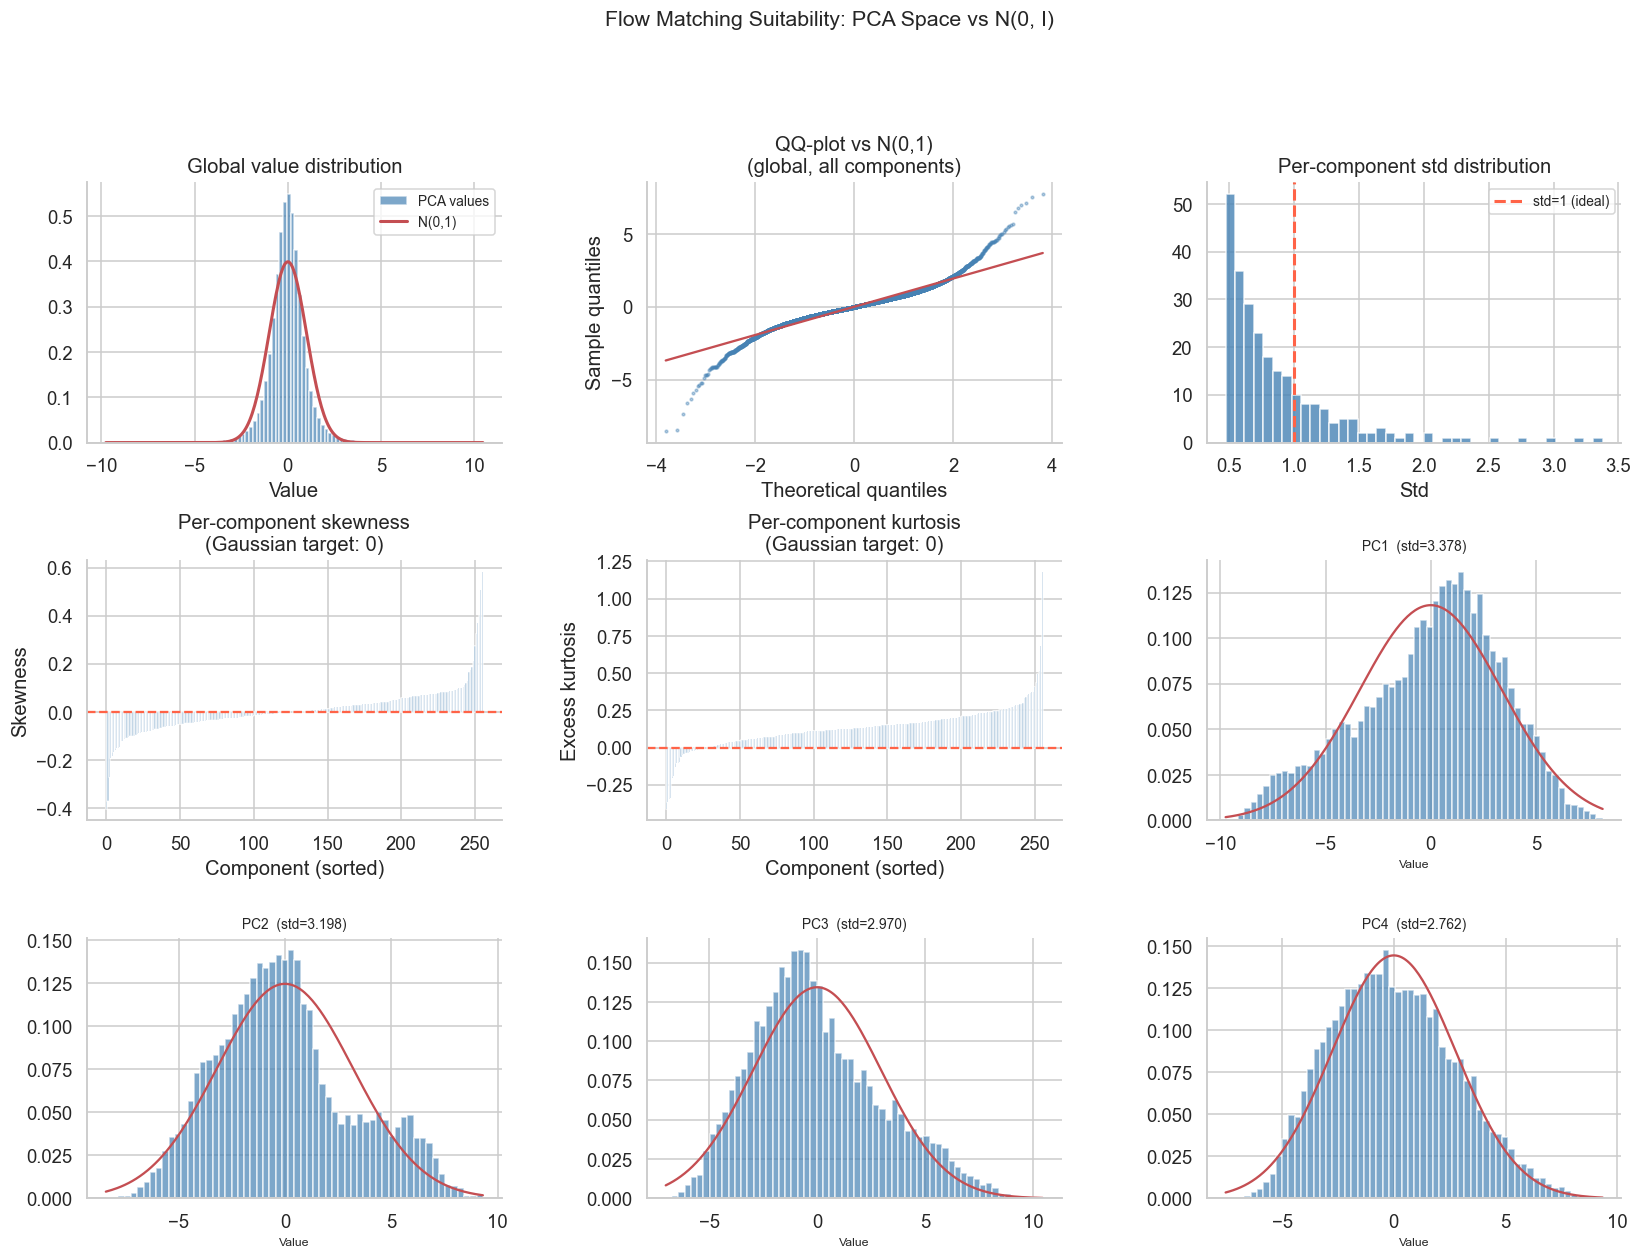

In [9]:
# Визуализация распределений
fig = plt.figure(figsize=(18, 12))
gs  = gridspec.GridSpec(3, 3, figure=fig, hspace=0.45, wspace=0.35)

# --- Глобальное распределение значений vs N(0,1) ---
ax = fig.add_subplot(gs[0, 0])
vals = emb_pca.ravel()
ax.hist(vals, bins=100, density=True, color='steelblue', alpha=0.7, edgecolor='white', label='PCA values')
x = np.linspace(vals.min(), vals.max(), 300)
ax.plot(x, stats.norm.pdf(x), 'r-', lw=2, label='N(0,1)')
ax.set_xlabel('Value')
ax.set_title('Global value distribution')
ax.legend(fontsize=9)

# --- QQ-plot глобальный ---
ax = fig.add_subplot(gs[0, 1])
sample_for_qq = rng.choice(vals, size=min(10000, len(vals)), replace=False)
qq = stats.probplot(sample_for_qq, dist='norm')
ax.scatter(qq[0][0], qq[0][1], s=3, alpha=0.4, color='steelblue')
xmin, xmax = qq[0][0].min(), qq[0][0].max()
ax.plot([xmin, xmax], [qq[1][1] + qq[1][0]*xmin, qq[1][1] + qq[1][0]*xmax],
        'r-', lw=1.5)
ax.set_xlabel('Theoretical quantiles')
ax.set_ylabel('Sample quantiles')
ax.set_title('QQ-plot vs N(0,1)\n(global, all components)')

# --- Per-dim std distribution ---
ax = fig.add_subplot(gs[0, 2])
ax.hist(emb_pca.std(axis=0), bins=40, color='steelblue', alpha=0.8, edgecolor='white')
ax.axvline(1.0, color='tomato', ls='--', lw=2, label='std=1 (ideal)')
ax.set_xlabel('Std')
ax.set_title('Per-component std distribution')
ax.legend(fontsize=9)

# --- Skewness и kurtosis по компонентам ---
ax = fig.add_subplot(gs[1, 0])
ax.bar(range(N_COMPONENTS), np.sort(skewness), color='steelblue', alpha=0.7)
ax.axhline(0, color='tomato', ls='--', lw=1.5)
ax.set_xlabel('Component (sorted)')
ax.set_ylabel('Skewness')
ax.set_title('Per-component skewness\n(Gaussian target: 0)')

ax = fig.add_subplot(gs[1, 1])
ax.bar(range(N_COMPONENTS), np.sort(kurtosis), color='steelblue', alpha=0.7)
ax.axhline(0, color='tomato', ls='--', lw=1.5)
ax.set_xlabel('Component (sorted)')
ax.set_ylabel('Excess kurtosis')
ax.set_title('Per-component kurtosis\n(Gaussian target: 0)')

# --- Первые 6 компонент: histogram + N(0,1) ---
axes_comp = [fig.add_subplot(gs[2, j]) for j in range(3)]
axes_comp2 = [fig.add_subplot(gs[1, 2])]
six_axes = axes_comp2 + axes_comp  # 4 штуки, возьмём первые 4 компоненты

for i, ax in enumerate(six_axes):
    comp_vals = emb_pca[:, i]
    ax.hist(comp_vals, bins=60, density=True, color='steelblue', alpha=0.7, edgecolor='white')
    x_c = np.linspace(comp_vals.min(), comp_vals.max(), 200)
    ax.plot(x_c, stats.norm.pdf(x_c, comp_vals.mean(), comp_vals.std()), 'r-', lw=1.5)
    ax.set_title(f'PC{i+1}  (std={comp_vals.std():.3f})', fontsize=9)
    ax.set_xlabel('Value', fontsize=8)

plt.suptitle('Flow Matching Suitability: PCA Space vs N(0, I)', fontsize=14, y=1.01)
plt.show()

In [10]:
# Shapiro-Wilk тест (на подвыборке) для первых 20 компонент
print('Shapiro-Wilk normality test (first 20 components, n=500 sample):')
print(f'  {"Component":<12} {"Statistic":>10} {"p-value":>12} {"Normal?"}' )
print('  ' + '-' * 52)
for i in range(20):
    sample = rng.choice(emb_pca[:, i], size=500, replace=False)
    stat, pval = stats.shapiro(sample)
    normal = 'YES' if pval > 0.05 else 'NO'
    print(f'  PC{i+1:<10d} {stat:>10.4f} {pval:>12.4e}   {normal}')

Shapiro-Wilk normality test (first 20 components, n=500 sample):
  Component     Statistic      p-value Normal?
  ----------------------------------------------------
  PC1              0.9763   3.0826e-07   NO
  PC2              0.9802   2.5537e-06   NO
  PC3              0.9805   3.0046e-06   NO
  PC4              0.9915   5.8430e-03   NO
  PC5              0.9954   1.4293e-01   YES
  PC6              0.9782   8.2650e-07   NO
  PC7              0.9926   1.4072e-02   NO
  PC8              0.9888   7.3658e-04   NO
  PC9              0.9977   7.3544e-01   YES
  PC10             0.9976   6.8836e-01   YES
  PC11             0.9959   2.2489e-01   YES
  PC12             0.9971   5.2061e-01   YES
  PC13             0.9792   1.4705e-06   NO
  PC14             0.9951   1.1808e-01   YES
  PC15             0.9926   1.3940e-02   NO
  PC16             0.9975   6.7253e-01   YES
  PC17             0.9901   1.8950e-03   NO
  PC18             0.9963   2.9358e-01   YES
  PC19             0.9982   8.899

In [11]:
# Итоговое резюме
print('=' * 60)
print('SUMMARY: PCA Space Analysis')
print('=' * 60)
print(f'Dimensionality:   3072d → {N_COMPONENTS}d  ({3072/N_COMPONENTS:.0f}x compression)')
print(f'Variance explained:  {cum_var[N_COMPONENTS-1]:.1f}%')
print()
print('Geometry (256d):')
print(f'  Mean cosine sim:    {cos_pca.mean():.4f}  (3072d: {cos_raw.mean():.4f})')
print(f'  Row norm:           mean={norms_pca.mean():.2f}, std={norms_pca.std():.3f}')
print()
print(f'Neighbor preservation:')
for k in K_VALUES:
    print(f'  Recall@{k:2d}:          {recalls[k]:.4f}')
print()
print('Gaussianity (for Flow Matching):')
print(f'  Global std:         {emb_pca.std():.4f}  (target: 1.0)')
print(f'  Mean skewness:      {skewness.mean():.4f}  (Gaussian: 0)')
print(f'  Mean kurtosis:      {kurtosis.mean():.4f}  (Gaussian: 0)')
print('=' * 60)

SUMMARY: PCA Space Analysis
Dimensionality:   3072d → 256d  (12x compression)
Variance explained:  78.2%

Geometry (256d):
  Mean cosine sim:    0.0000  (3072d: 0.2685)
  Row norm:           mean=15.98, std=0.712

Neighbor preservation:
  Recall@ 1:          0.8080
  Recall@ 5:          0.8320
  Recall@10:          0.8378
  Recall@20:          0.8384
  Recall@50:          0.8337

Gaussianity (for Flow Matching):
  Global std:         1.0000  (target: 1.0)
  Mean skewness:      0.0053  (Gaussian: 0)
  Mean kurtosis:      0.1316  (Gaussian: 0)
